# TESS analysis - LCF

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

%matplotlib inline

import pickle

In [39]:
sector23_lcf = "/home/michael/labo_2/TESS_analysis/HATP12_sector23_lc.fits"
fits.info(sector23_lcf)

Filename: /home/michael/labo_2/TESS_analysis/HATP12_sector23_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      44   ()      
  1  LIGHTCURVE    1 BinTableHDU    167   19279R x 20C   [D, E, J, E, E, E, E, E, E, J, D, E, D, E, D, E, D, E, E, E]   
  2  APERTURE      1 ImageHDU        49   (11, 11)   int32   


In [40]:
lchdu = fits.open(sector23_lcf)
lchdu[1].columns
# lchdu[1].header
# lchdu[1].data

ColDefs(
    name = 'TIME'; format = 'D'; unit = 'BJD - 2457000, days'; disp = 'D14.7'
    name = 'TIMECORR'; format = 'E'; unit = 'd'; disp = 'E14.7'
    name = 'CADENCENO'; format = 'J'; disp = 'I10'
    name = 'SAP_FLUX'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_FLUX_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_BKG'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'SAP_BKG_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'PDCSAP_FLUX'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'PDCSAP_FLUX_ERR'; format = 'E'; unit = 'e-/s'; disp = 'E14.7'
    name = 'QUALITY'; format = 'J'; disp = 'B16.16'
    name = 'PSF_CENTR1'; format = 'D'; unit = 'pixel'; disp = 'F10.5'
    name = 'PSF_CENTR1_ERR'; format = 'E'; unit = 'pixel'; disp = 'E14.7'
    name = 'PSF_CENTR2'; format = 'D'; unit = 'pixel'; disp = 'F10.5'
    name = 'PSF_CENTR2_ERR'; format = 'E'; unit = 'pixel'; disp = 'E14.7'
    name = 'MOM_CENTR1'; format = 'D'; u

Extract data of interest

In [41]:
# time + reference time integral and fractionary part
time_array = lchdu[1].data['TIME'] + lchdu[1].header['BJDREFI'] + lchdu[1].header['BJDREFF']
sap_flux = lchdu[1].data['SAP_FLUX']
sap_flux_error = lchdu[1].data['SAP_FLUX_ERR']
pdcsap_flux = lchdu[1].data['PDCSAP_FLUX']
pdcsap_flux_error = lchdu[1].data['PDCSAP_FLUX_ERR']

PDCSAP is the corrected one form systematics\
Pre-search-data condition\
some points may even disappear (nan)

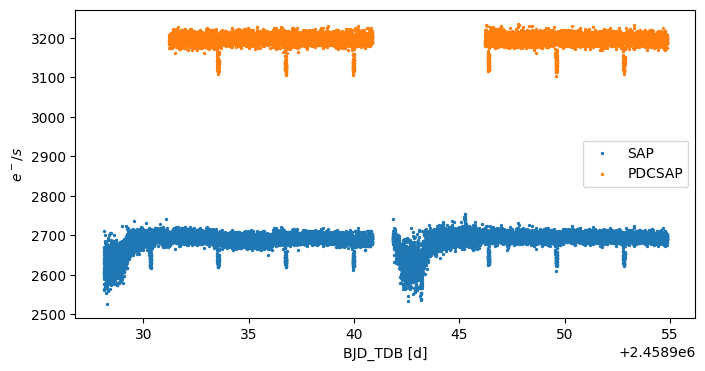

In [42]:
plt.figure(figsize=(8,4))
plt.scatter(time_array, sap_flux, s=2, label='SAP')
plt.scatter(time_array, pdcsap_flux, s=2, label='PDCSAP')
plt.xlabel('BJD_TDB [d]')
plt.ylabel('$e^-/s$')
plt.legend()
plt.show()

In [43]:
print(np.shape(sap_flux), np.shape(pdcsap_flux), np.shape(time_array))

np.average(pdcsap_flux)

(19279,) (19279,) (19279,)


nan

Exclude nan values and compute average

In [45]:
finite_selection = np.isfinite(pdcsap_flux)
np.average(pdcsap_flux[finite_selection])

3195.5693

Quality flag associated with each enter

check left side table to convert to errors?\
https://outerspace.stsci.edu/spaces/TESS/pages/14563420/2.0+-+Data+Product+Overview#id-2.0DataProductOverview-Table%3ACadenceQualityFlags

In [66]:
quality = lchdu[1].data['QUALITY']
print(quality)
# print(np.shape(quality))

# binary representation
for q in quality:
    np.binary_repr(q)

# pass the whole array to binary_repr
binary_repr_vec = np.vectorize(np.binary_repr)
bin_quality = binary_repr_vec(quality)

print(bin_quality)

[ 40  32 160 ... 128   0   0]
['101000' '100000' '10100000' ... '10000000' '0' '0']


Conservative selection, use values of quality bitmask = 0

In [64]:
conservative_selection = (quality == 0) & finite_selection
print(conservative_selection)

# number of points that survived the selection
np.sum(conservative_selection)

[False False False ... False  True  True]


12411

In [70]:
flags_to_be_checked = np.array(np.array([1,2,3,4,5,6,8,10,13,15]))
reference_bitmask_in_decimal_system = 0
for v in flags_to_be_checked:
    reference_bitmask_in_decimal_system += 2**(v-1)

# integer number when all flags all true
print(reference_bitmask_in_decimal_system)

np.binary_repr(reference_bitmask_in_decimal_system)

21183


'101001010111111'

Compare reference bitmask to each value of quality bitmask, use and operation 0 and 1 = 0

In [79]:
example_quality = 32
np.binary_repr(example_quality)

print(np.bitwise_and(reference_bitmask_in_decimal_system, example_quality))

32


Better selection, conservative just avoid any error, this one just the selected flags

In [82]:
selective_selection = (np.bitwise_and(reference_bitmask_in_decimal_system, quality) == 0) & finite_selection

np.sum(selective_selection)

12411

Re-plot without excluded data

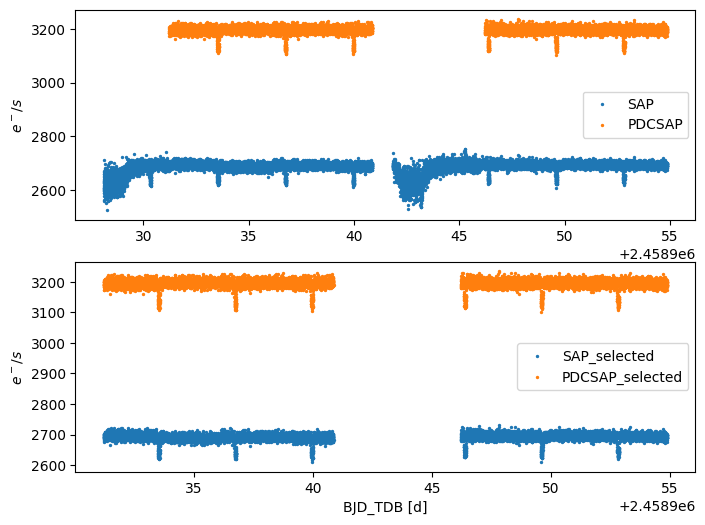

In [95]:
fig, ax = plt.subplots(2, figsize=(8,6))
ax[0].scatter(time_array, sap_flux, s=2, label='SAP')
ax[0].scatter(time_array, pdcsap_flux, s=2, label='PDCSAP')
ax[1].scatter(time_array[selective_selection], sap_flux[selective_selection], s=2, label='SAP_selected')
ax[1].scatter(time_array[selective_selection], pdcsap_flux[selective_selection], s=2, label='PDCSAP_selected')

ax[1].set_xlabel('BJD_TDB [d]')
ax[0].set_ylabel('$e^-/s$')
ax[1].set_ylabel('$e^-/s$')
ax[0].legend()
ax[1].legend()
plt.show()

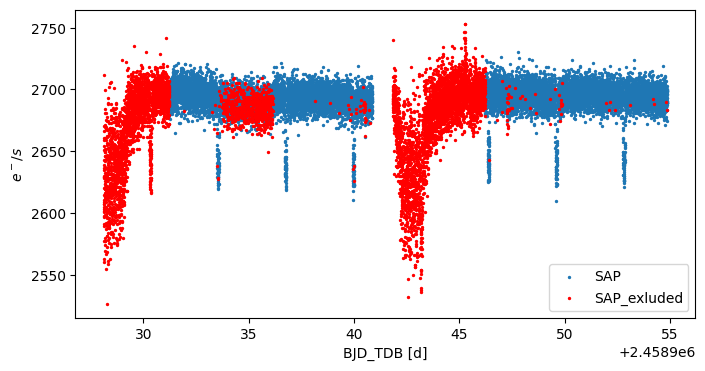

In [97]:
plt.figure(figsize=(8,4))
plt.scatter(time_array[selective_selection], sap_flux[selective_selection], s=2, label='SAP')
plt.scatter(time_array[~selective_selection], sap_flux[~selective_selection], s=2, label='SAP_exluded', c='r')
plt.xlabel('BJD_TDB [d]')
plt.ylabel('$e^-/s$')
plt.legend()
plt.show()

If transit happen just after excluded data there may be problems, to use this region to fit and get value of baseline use a specific algorithm

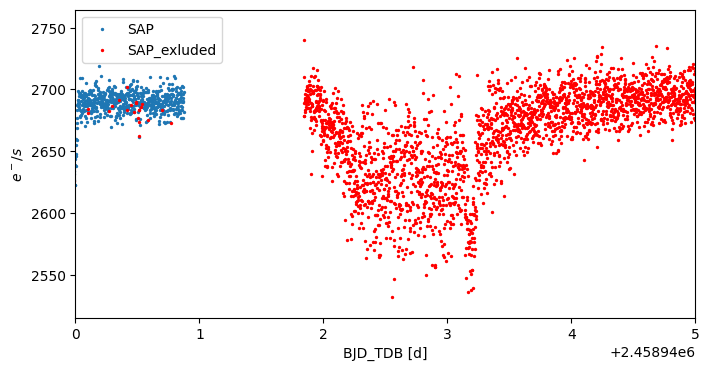

In [102]:
plt.figure(figsize=(8,4))
plt.scatter(time_array[selective_selection], sap_flux[selective_selection], s=2, label='SAP')
plt.scatter(time_array[~selective_selection], sap_flux[~selective_selection], s=2, label='SAP_exluded', c='r')
plt.xlabel('BJD_TDB [d]')
plt.ylabel('$e^-/s$')
plt.xlim(2458940,2458945 )
plt.legend()
plt.show()

In [ ]:
final_selection = conservative_selection & (time_array > valore nostro)